# Unsupervised immune patterns in TCGA-KIRC

K-means and hierarchical clustering group patients from the immune-cell proportions themselves. Age, sex, stage, grade, and survival are not used to build the groups or to choose the number of groups. Those variables are used only afterward to describe the groups. A check at the end compresses the same features with PCA and repeats the clustering.

All 533 patients with an immune profile are included. Patients with short follow-up stay in the clustering.

It reads the two data files from My Drive


In [1]:

!pip install -q lifelines openpyxl


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


This step installs lifelines and openpyxl.



In [2]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

try:
    from IPython.display import display
except ImportError:
    display = print

# settings used later
random_state = 6
zero_drop_threshold = 0.90
variance_target = 0.80
k_range = range(2, 9)  # try 2, 3, 4, 5, 6, 7, and 8 groups
min_cluster_fraction = 0.05
days_3y = 365 * 3
year_days = 365.25

# also keep the old names so the rest of the notebook can use them
RANDOM_STATE = random_state
ZERO_DROP_THRESHOLD = zero_drop_threshold
VARIANCE_TARGET = variance_target
K_RANGE = k_range
MIN_CLUSTER_FRACTION = min_cluster_fraction
DAYS_3Y = days_3y
YEAR_DAYS = year_days

# Colab reads the files from Google Drive.
# Anywhere else, read the copies in data/raw of the repo.
try:
    from google.colab import drive
    use_google_drive = True
except ImportError:
    use_google_drive = False

if use_google_drive:
    drive.mount("/content/drive", force_remount=True)
    # the two data files sit in My Drive itself, not in a subfolder
    DRIVE_DIR = Path("/content/drive/MyDrive")
    CDR_FILE = DRIVE_DIR / "TCGA-CDR-SupplementalTableS1.xlsx"
    IMMUNE_FILE = DRIVE_DIR / "TCGA.Kallisto.fullIDs.cibersort.relative.tsv"
else:
    DRIVE_DIR = None
    for folder in [Path.cwd(), *Path.cwd().parents]:
        clinical_path = folder / "data" / "raw" / "TCGA-CDR-SupplementalTableS1.xlsx"
        immune_path = folder / "data" / "raw" / "TCGA.Kallisto.fullIDs.cibersort.relative.tsv"
        if clinical_path.exists() and immune_path.exists():
            DRIVE_DIR = folder
            CDR_FILE = clinical_path
            IMMUNE_FILE = immune_path
            break
    if DRIVE_DIR is None:
        raise FileNotFoundError("Could not find data/raw. Open this notebook from inside the repo folder.")

# folders for the saved files
OUT_DIR = DRIVE_DIR / "SIADS_696_outputs"
PROCESSED_DIR = OUT_DIR / "processed"
FIGURE_DIR = OUT_DIR / "figures"
TABLE_DIR = OUT_DIR / "tables"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Clinical file:", CDR_FILE)
print("Immune file:", IMMUNE_FILE)
print("Outputs will be saved to:", OUT_DIR)

# the 22 immune cell types in the CIBERSORT file
IMMUNE_COLUMNS = [
    "B.cells.naive",
    "B.cells.memory",
    "Plasma.cells",
    "T.cells.CD8",
    "T.cells.CD4.naive",
    "T.cells.CD4.memory.resting",
    "T.cells.CD4.memory.activated",
    "T.cells.follicular.helper",
    "T.cells.regulatory..Tregs.",
    "T.cells.gamma.delta",
    "NK.cells.resting",
    "NK.cells.activated",
    "Monocytes",
    "Macrophages.M0",
    "Macrophages.M1",
    "Macrophages.M2",
    "Dendritic.cells.resting",
    "Dendritic.cells.activated",
    "Mast.cells.resting",
    "Mast.cells.activated",
    "Eosinophils",
    "Neutrophils",
]

# shorter names for the plots
DISPLAY_NAMES = {
    "B.cells.naive": "B cells, naive",
    "B.cells.memory": "B cells, memory",
    "Plasma.cells": "Plasma cells",
    "T.cells.CD8": "CD8 T cells",
    "T.cells.CD4.naive": "CD4 T cells, naive",
    "T.cells.CD4.memory.resting": "CD4 T cells, memory resting",
    "T.cells.CD4.memory.activated": "CD4 T cells, memory activated",
    "T.cells.follicular.helper": "Follicular helper T cells",
    "T.cells.regulatory..Tregs.": "Regulatory T cells",
    "T.cells.gamma.delta": "Gamma-delta T cells",
    "NK.cells.resting": "NK cells, resting",
    "NK.cells.activated": "NK cells, activated",
    "Monocytes": "Monocytes",
    "Macrophages.M0": "Macrophages M0",
    "Macrophages.M1": "Macrophages M1",
    "Macrophages.M2": "Macrophages M2",
    "Dendritic.cells.resting": "Dendritic cells, resting",
    "Dendritic.cells.activated": "Dendritic cells, activated",
    "Mast.cells.resting": "Mast cells, resting",
    "Mast.cells.activated": "Mast cells, activated",
    "Eosinophils": "Eosinophils",
    "Neutrophils": "Neutrophils",
}

# these text values mean the stage or grade is missing
MISSING_CLINICAL = ["[Not Available]", "[Discrepancy]", "GX", "[Unknown]", "[Not Applicable]"]
STAGE_ORDER = ["Stage I", "Stage II", "Stage III", "Stage IV", "Unknown"]
GRADE_ORDER = ["G1", "G2", "G3", "G4", "Unknown"]
CLUSTER_COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9", "#F0E442", "#000000"]


def display_name(column):
    if column in DISPLAY_NAMES:
        return DISPLAY_NAMES[column]
    return column


sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


Mounted at /content/drive
Clinical file: /content/drive/MyDrive/TCGA-CDR-SupplementalTableS1.xlsx
Immune file: /content/drive/MyDrive/TCGA.Kallisto.fullIDs.cibersort.relative.tsv
Outputs will be saved to: /content/drive/MyDrive/SIADS_696_outputs


This step connects Google Drive and points to the two data files in My Drive. Outputs go to SIADS_696_outputs. The notebook prints the clinical file path, the immune file path, and the output folder. Later cells read those two files and write figures and tables into that output folder.



## 1. Build the patient cohort

Keep KIRC primary tumors only. If a patient has more than one primary-tumor sample, keep the stronger CIBERSORT fit: lower P-value, then lower RMSE, then higher correlation. Join that sample to the clinical record. Patients with short follow-up stay in the cohort. The three-year label is stored for description and is not used in the model.


In [3]:
# read the clinical Excel file and the immune file
clinical_all = pd.read_excel(CDR_FILE, sheet_name="TCGA-CDR")
immune_all = pd.read_csv(IMMUNE_FILE, sep="\t")

# keep kidney cancer only
clinical = clinical_all[clinical_all["type"] == "KIRC"].copy()
clinical = clinical.rename(columns={"bcr_patient_barcode": "patient_id"})
if clinical["patient_id"].duplicated().any():
    raise ValueError("Clinical KIRC patient IDs are not unique.")

immune = immune_all[immune_all["CancerType"] == "KIRC"].copy()

# one file uses dots in the sample id and the other uses dashes
immune["sample_barcode"] = immune["SampleID"].astype(str).str.replace(".", "-", regex=False)

# patient id is the first three pieces, like TCGA-XX-XXXX
immune["patient_id"] = immune["sample_barcode"].str.extract(r"^(TCGA-[^-]+-[^-]+)")

# 01 means this sample is the primary tumor
immune["sample_type"] = immune["sample_barcode"].str.extract(r"^TCGA-[^-]+-[^-]+-(\d{2})")
if immune["patient_id"].isna().any():
    raise ValueError("Some KIRC sample IDs could not be parsed.")

primary = immune[immune["sample_type"] == "01"].copy()

# some patients have two primary samples
dup_rows = primary["patient_id"].duplicated(keep=False)
duplicate_patients = int(primary.loc[dup_rows, "patient_id"].nunique())

# if there are two samples, keep the stronger CIBERSORT fit
primary = primary.sort_values(
    ["patient_id", "P.value", "RMSE", "Correlation", "SampleID"],
    ascending=[True, True, True, False, True],
)
one_sample = primary.drop_duplicates("patient_id", keep="first").copy()

# clinical columns we want to join on later
clinical_columns = [
    "patient_id",
    "age_at_initial_pathologic_diagnosis",
    "gender",
    "ajcc_pathologic_tumor_stage",
    "histological_grade",
    "OS",
    "OS.time",
]
clinical = clinical[clinical_columns].copy()
clinical["ajcc_pathologic_tumor_stage"] = clinical["ajcc_pathologic_tumor_stage"].replace(MISSING_CLINICAL, np.nan)
clinical["histological_grade"] = clinical["histological_grade"].replace(MISSING_CLINICAL, np.nan)
clinical["age_at_initial_pathologic_diagnosis"] = pd.to_numeric(clinical["age_at_initial_pathologic_diagnosis"], errors="coerce")
clinical["OS"] = pd.to_numeric(clinical["OS"], errors="coerce")
clinical["OS.time"] = pd.to_numeric(clinical["OS.time"], errors="coerce")

immune_keep = ["patient_id", "sample_barcode", "P.value", "Correlation", "RMSE"]
for column in IMMUNE_COLUMNS:
    immune_keep.append(column)

# one row per patient
merged = clinical.merge(one_sample[immune_keep], on="patient_id", how="inner", validate="one_to_one")

# this 3-year label is only for the count below. It is not used to make the groups.
died_within_3y = (merged["OS"] == 1) & (merged["OS.time"] <= DAYS_3Y)
survived_3y = (merged["OS.time"] > DAYS_3Y) | ((merged["OS"] == 0) & (merged["OS.time"] >= DAYS_3Y))
merged["survival_3y"] = np.select([died_within_3y, survived_3y], [0, 1], default=np.nan)

counts = pd.DataFrame(
    [
        ("KIRC clinical patients", len(clinical)),
        ("KIRC immune samples", len(immune)),
        ("KIRC primary tumor samples", len(primary)),
        ("Patients with a primary tumor sample", primary["patient_id"].nunique()),
        ("Patients with more than one primary sample", duplicate_patients),
        ("Patients after keeping one sample", len(one_sample)),
        ("Patients in the clustering cohort", len(merged)),
        ("Patients with CIBERSORT P <= 0.05", int((merged["P.value"] <= 0.05).sum())),
        ("Patients with a known 3-year outcome", int(merged["survival_3y"].notna().sum())),
    ],
    columns=["step", "n"],
)

cohort = merged.reset_index(drop=True)
display(counts)


,step,n
0,KIRC clinical patients,537
1,KIRC immune samples,618
2,KIRC primary tumor samples,545
3,Patients with a primary tumor sample,533
4,Patients with more than one primary sample,8
5,Patients after keeping one sample,533
6,Patients in the clustering cohort,533
7,Patients with CIBERSORT P <= 0.05,368
8,Patients with a known 3-year outcome,404


This step keeps KIRC primary tumors, keeps one sample per patient, and joins the clinical record, including patients with short follow up. The result is 533 patients. Eight of them had two primary samples, and the stronger CIBERSORT fit was kept. Of these 533, 404 have a known three year outcome. Clustering uses all 533 immune profiles.



## 2. Choose the immune features

Each row of 22 proportions sums to 1. Cell types that are zero in at least 90% of patients are dropped before scaling, because standardization would turn those rare nonzero values into extreme distances. The remaining proportions are rescaled to sum to 1.


In [4]:
# count how often each cell type is zero
rows = []
for column in IMMUNE_COLUMNS:
    values = cohort[column]
    zero_rate = (values == 0).mean()
    rows.append(
        {
            "feature": column,
            "display_name": display_name(column),
            "zero_percent": 100 * zero_rate,
            "mean_proportion": values.mean(),
            "std_proportion": values.std(ddof=1),
            "used_in_model": zero_rate < ZERO_DROP_THRESHOLD,
        }
    )

zero_table = pd.DataFrame(rows)
zero_table = zero_table.sort_values("zero_percent", ascending=False)

# drop a cell type if it is zero for at least 90% of patients
used_features = []
dropped_names = []
for feature in IMMUNE_COLUMNS:
    keep_this = zero_table.loc[zero_table["feature"] == feature, "used_in_model"].iloc[0]
    if keep_this:
        used_features.append(feature)
    else:
        dropped_names.append(display_name(feature))

proportions = cohort[used_features]

if proportions.isna().any().any():
    raise ValueError("Immune proportions contain missing values.")
if not np.allclose(cohort[IMMUNE_COLUMNS].sum(axis=1), 1.0, atol=1e-6):
    raise ValueError("Immune proportions do not sum to 1.")

display(zero_table.round(4))
print("Features used:", len(used_features))
print("Dropped:", ", ".join(dropped_names))


,feature,display_name,zero_percent,mean_proportion,std_proportion,used_in_model
4,T.cells.CD4.naive,"CD4 T cells, naive",97.9362,0.0011,0.0107,False
20,Eosinophils,Eosinophils,94.5591,0.0005,0.0032,False
6,T.cells.CD4.memory.activated,"CD4 T cells, memory activated",92.3077,0.0013,0.0072,False
9,T.cells.gamma.delta,Gamma-delta T cells,84.2402,0.0033,0.0106,True
17,Dendritic.cells.activated,"Dendritic cells, activated",72.2326,0.0041,0.0134,True
19,Mast.cells.activated,"Mast cells, activated",70.7317,0.0100,0.0262,True
13,Macrophages.M0,Macrophages M0,69.7936,0.0181,0.0534,True
16,Dendritic.cells.resting,"Dendritic cells, resting",68.6679,0.0049,0.0201,True
1,B.cells.memory,"B cells, memory",68.4803,0.0059,0.0156,True
10,NK.cells.resting,"NK cells, resting",63.0394,0.0160,0.0295,True


Features used: 19
Dropped: CD4 T cells, naive, CD4 T cells, memory activated, Eosinophils


This step counts how often each of the 22 immune cell types is zero and drops any cell type that is zero in at least 90% of patients. Nineteen cell types stay. Naive CD4 T cells, activated memory CD4 T cells, and eosinophils are dropped because they are too rare to define a group. After scaling, their few nonzero values would look like extreme outliers.



## 3. Prepare the 19 immune features

The three cell types that are zero in at least 90% of patients are already removed. The remaining values are rescaled so each patient sums to 1. Remaining zeros are filled with a small placeholder, a centered log-ratio is applied, and the 19 features are standardized. These 19 values are the input to both clustering methods.



In [5]:
# after dropping rare cell types, make each patient sum to 1 again
row_sums = proportions.sum(axis=1)
if (row_sums <= 0).any():
    raise ValueError("At least one patient has no remaining immune proportion.")
closed = proportions.div(row_sums, axis=0)

# zeros cannot go into a log, so fill each zero with a very small number
values = closed.to_numpy(dtype=float)
n_rows = values.shape[0]
n_cols = values.shape[1]
deltas = np.empty(n_cols)

for j in range(n_cols):
    positive = values[values[:, j] > 0, j]
    if len(positive) == 0:
        raise ValueError(str(closed.columns[j]) + " has no positive values.")
    deltas[j] = 0.5 * positive.min()

replaced_values = values.copy()
for i in range(n_rows):
    zero = values[i] <= 0
    if not np.any(zero):
        continue
    zero_mass = float(deltas[zero].sum())
    row_deltas = deltas[zero]
    if zero_mass >= 1:
        row_deltas = deltas[zero] * (0.1 / zero_mass)
        zero_mass = float(row_deltas.sum())
    replaced_values[i, zero] = row_deltas
    replaced_values[i, ~zero] = values[i, ~zero] * (1.0 - zero_mass)

if np.any(replaced_values <= 0):
    raise ValueError("Zero replacement produced a non-positive value.")

replaced_values = replaced_values / replaced_values.sum(axis=1, keepdims=True)
replaced = pd.DataFrame(replaced_values, index=closed.index, columns=closed.columns)
delta_table = pd.DataFrame({"feature": list(closed.columns), "replacement_value": deltas})

# centered log-ratio: log each value, then subtract the row mean
logged = np.log(replaced_values)
row_mean = logged.mean(axis=1)
clr_values = logged - row_mean[:, None]
clr = pd.DataFrame(clr_values, index=replaced.index, columns=replaced.columns)

# put every cell type on the same scale
scaler = StandardScaler()
scaled = scaler.fit_transform(clr)

# a group has to have at least 5% of the patients
min_size = int(np.ceil(MIN_CLUSTER_FRACTION * len(proportions)))

print("Patients:", scaled.shape[0])
print("Features:", scaled.shape[1])
print("Minimum group size:", min_size)


Patients: 533
Features: 19
Minimum group size: 27


This step rescales the 19 cell types so each patient sums to 1, fills the remaining zeros, applies a centered log ratio  and standardizes the values. The result is a table of 533 patients by 19 features, and each group later must have at least 27 patients. The cell types can now be compared on the same scale. These 19 numbers are what both clustering methods use.



## 4. K-means

K-means is fit on the 19 standardized features for 2 through 8 groups. The chosen solution has the highest silhouette score among solutions in which every group holds at least 5% of patients. Group numbers are ordered by size.



In [6]:
# number the biggest group as group 1
def relabel_by_size(labels):
    counts = pd.Series(labels).value_counts()
    order = sorted(counts.index, key=lambda cluster: (-counts[cluster], int(cluster)))
    mapping = {}
    new_number = 1
    for old_number in order:
        mapping[old_number] = new_number
        new_number = new_number + 1
    new_labels = []
    for cluster in labels:
        new_labels.append(mapping[cluster])
    return np.array(new_labels)


def choose_k_means(feature_matrix, minimum_size):
    rows = []
    fitted = {}
    for k in K_RANGE:
        model = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE)
        raw_labels = model.fit_predict(feature_matrix)
        labels = relabel_by_size(raw_labels)
        sizes = np.bincount(labels)[1:]
        rows.append(
            {
                "k": k,
                "silhouette": silhouette_score(feature_matrix, labels),
                "calinski_harabasz": calinski_harabasz_score(feature_matrix, labels),
                "davies_bouldin": davies_bouldin_score(feature_matrix, labels),
                "min_cluster_size": int(sizes.min()),
                "max_cluster_size": int(sizes.max()),
                "meets_size_rule": bool(sizes.min() >= minimum_size),
            }
        )
        fitted[k] = labels

    table = pd.DataFrame(rows)

    # keep the k with the best silhouette, but every group must be big enough
    eligible = table[table["meets_size_rule"] == True]
    if len(eligible) == 0:
        raise ValueError("No k met the minimum group-size rule.")
    best_row = eligible["silhouette"].idxmax()
    chosen = int(eligible.loc[best_row, "k"])
    return table, chosen, fitted[chosen]


kmeans_table, kmeans_k, kmeans_labels = choose_k_means(scaled, min_size)
print("K-means groups:", kmeans_k)
display(kmeans_table.round(3))


K-means groups: 2


,k,silhouette,calinski_harabasz,davies_bouldin,min_cluster_size,max_cluster_size,meets_size_rule
0,2,0.127,75.767,2.557,232,301,True
1,3,0.106,61.619,2.471,132,217,True
2,4,0.113,53.720,2.117,14,210,False
3,5,0.099,49.411,2.075,14,167,False
4,6,0.096,46.198,2.223,15,148,False
5,7,0.103,43.830,2.133,15,149,False
6,8,0.100,41.496,2.124,15,129,False


This step runs k-means for 2 through 8 groups and keeps the highest silhouette score where every group has at least 5% of patients. The result is 2 groups, with 301 and 232 patients, and a silhouette score of 0.13. Two groups fit better than more groups, but 0.13 is a weak score. The patients overlap rather than forming two tight groups.



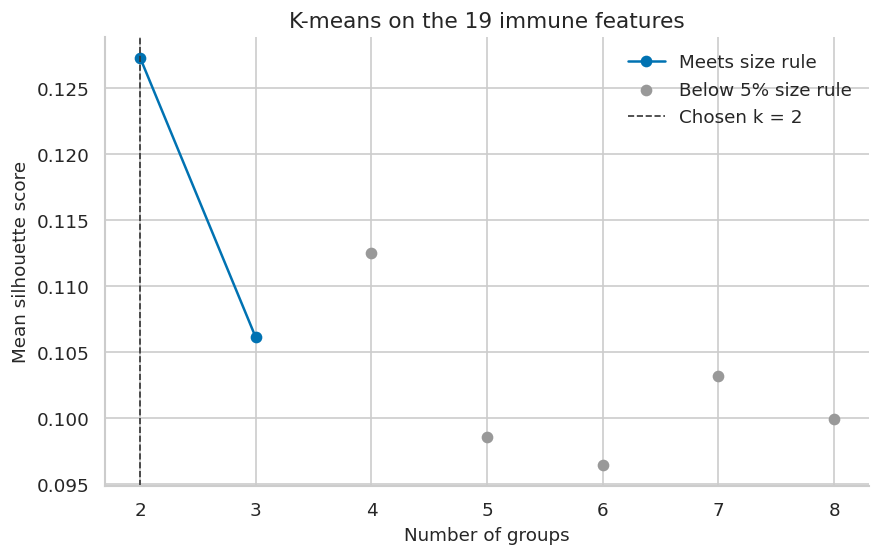

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))

# blue line = group counts that pass the 5% rule
ok = kmeans_table["meets_size_rule"]
ax.plot(
    kmeans_table.loc[ok, "k"],
    kmeans_table.loc[ok, "silhouette"],
    marker="o",
    color="#0072B2",
    label="Meets size rule",
)

# gray dots = a group was too small
too_small = ~ok
if too_small.any():
    ax.scatter(
        kmeans_table.loc[too_small, "k"],
        kmeans_table.loc[too_small, "silhouette"],
        color="#999999",
        label="Below 5% size rule",
    )

ax.axvline(kmeans_k, color="#333333", linestyle="--", linewidth=1, label="Chosen k = " + str(kmeans_k))
ax.set_xlabel("Number of groups")
ax.set_ylabel("Mean silhouette score")
ax.set_xticks(list(K_RANGE))
ax.set_title("K-means on the 19 immune features")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "kmeans_silhouette_selection.png", bbox_inches="tight")
plt.show()


This step plots the k-means silhouette score for each number of groups. The score is highest at 2 groups and then falls so adding more groups does not make the patients separate more cleanly.



## 5. Hierarchical clustering

Hierarchical clustering uses the same 19 standardized features and Euclidean distance. Ward's method joins the closest patients until everyone is in one tree. The tree is cut at 2 through 8 groups and the same silhouette and size rules choose the cut.



In [8]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

# build one tree, then cut it at 2 through 8 groups
link = linkage(scaled, method="ward", metric="euclidean")
hierarchical_rows = []
hierarchical_fits = {}

for k in K_RANGE:
    raw_labels = fcluster(link, t=k, criterion="maxclust")
    labels = relabel_by_size(raw_labels)
    sizes = np.bincount(labels)[1:]
    hierarchical_rows.append(
        {
            "k": k,
            "silhouette": silhouette_score(scaled, labels),
            "min_cluster_size": int(sizes.min()),
            "max_cluster_size": int(sizes.max()),
            "meets_size_rule": bool(sizes.min() >= min_size),
        }
    )
    hierarchical_fits[k] = labels

hierarchical_table = pd.DataFrame(hierarchical_rows)
hierarchical_eligible = hierarchical_table[hierarchical_table["meets_size_rule"] == True]
if len(hierarchical_eligible) == 0:
    raise ValueError("No hierarchical cut met the minimum group-size rule.")

best_row = hierarchical_eligible["silhouette"].idxmax()
hierarchical_k = int(hierarchical_eligible.loc[best_row, "k"])
hierarchical_labels = hierarchical_fits[hierarchical_k]

print("Hierarchical groups:", hierarchical_k)
display(hierarchical_table.round(3))


Hierarchical groups: 2


,k,silhouette,min_cluster_size,max_cluster_size,meets_size_rule
0,2,0.113,220,313,True
1,3,0.121,14,299,False
2,4,0.084,14,226,False
3,5,0.070,14,220,False
4,6,0.058,14,220,False
5,7,0.065,14,126,False
6,8,0.073,14,116,False


This step builds a clustering tree with Ward's method and cuts it at 2 through 8 groups using the same silhouette and size rules. The result is 2 groups with 313 and 220 patients and a silhouette score of 0.11. A 3 group cut scored 0.12, but one group had only 14 patients so it was not used. Hierarchical clustering also settles on two groups and the separation is a little weaker than k-means.



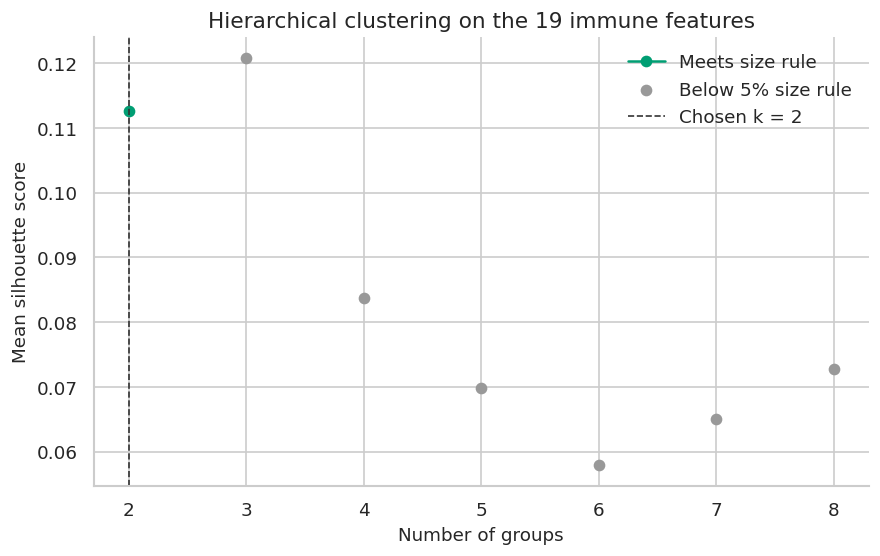

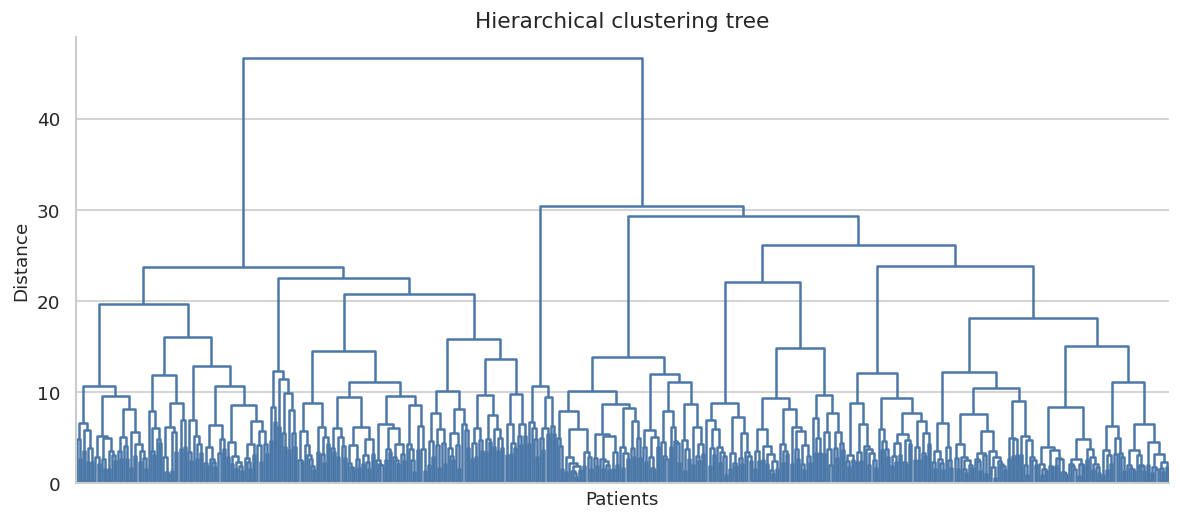

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))

ok = hierarchical_table["meets_size_rule"]
ax.plot(
    hierarchical_table.loc[ok, "k"],
    hierarchical_table.loc[ok, "silhouette"],
    marker="o",
    color="#009E73",
    label="Meets size rule",
)

too_small = ~ok
if too_small.any():
    ax.scatter(
        hierarchical_table.loc[too_small, "k"],
        hierarchical_table.loc[too_small, "silhouette"],
        color="#999999",
        label="Below 5% size rule",
    )

ax.axvline(hierarchical_k, color="#333333", linestyle="--", linewidth=1, label="Chosen k = " + str(hierarchical_k))
ax.set_xlabel("Number of groups")
ax.set_ylabel("Mean silhouette score")
ax.set_xticks(list(K_RANGE))
ax.set_title("Hierarchical clustering on the 19 immune features")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "hierarchical_silhouette_selection.png", bbox_inches="tight")
plt.show()

# the tree shows patients being joined step by step
fig, ax = plt.subplots(figsize=(10, 4.5))
dendrogram(link, no_labels=True, ax=ax, color_threshold=0, above_threshold_color="#4C78A8")
ax.set_xlabel("Patients")
ax.set_ylabel("Distance")
ax.set_title("Hierarchical clustering tree")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "hierarchical_dendrogram.png", bbox_inches="tight")
plt.show()


This step plots the hierarchical silhouette scores and the clustering tree. The allowed score is highest at 2 groups and the tree shows patients joined step by step into larger groups. The tree is one gradient of immune mixes not two widely separated blocks.



## 6. Compare the two groupings

The Adjusted Rand Index measures how often the two methods place the same patients together. A value near 1 means the groupings match. The silhouette scores compare how cleanly each method separates patients. Survival is not used in this comparison.



In [10]:
# 1.0 would mean the two methods put every patient in the same group
agreement = adjusted_rand_score(kmeans_labels, hierarchical_labels)

kmeans_sil = kmeans_table.loc[kmeans_table["k"] == kmeans_k, "silhouette"].iloc[0]
hierarchical_sil = hierarchical_table.loc[hierarchical_table["k"] == hierarchical_k, "silhouette"].iloc[0]

comparison = pd.DataFrame(
    [
        {
            "method": "K-means",
            "groups": kmeans_k,
            "silhouette": kmeans_sil,
            "adjusted_rand_vs_kmeans": 1.0,
        },
        {
            "method": "Hierarchical",
            "groups": hierarchical_k,
            "silhouette": hierarchical_sil,
            "adjusted_rand_vs_kmeans": agreement,
        },
    ]
)

print("Patients placed differently:")
display(pd.crosstab(
    pd.Series(kmeans_labels, name="K-means"),
    pd.Series(hierarchical_labels, name="Hierarchical"),
))
display(comparison.round(3))


Patients placed differently:


Hierarchical,1,2
K-means,,
1,280,21
2,33,199


,method,groups,silhouette,adjusted_rand_vs_kmeans
0,K-means,2,0.127,1.000
1,Hierarchical,2,0.113,0.635


This step compares which patients the two methods put in the same group. The Adjusted Rand Index is 0.64 and about 54 patients switch groups. The two methods mostly agree. The difference is the boundary between the groups not a different immune pattern.



## 7. Immune and clinical profiles

For each method the heatmap shows how far each group's average cell type is from the average patient in percentage points. Stage and grade are compared after the groups are fixed.



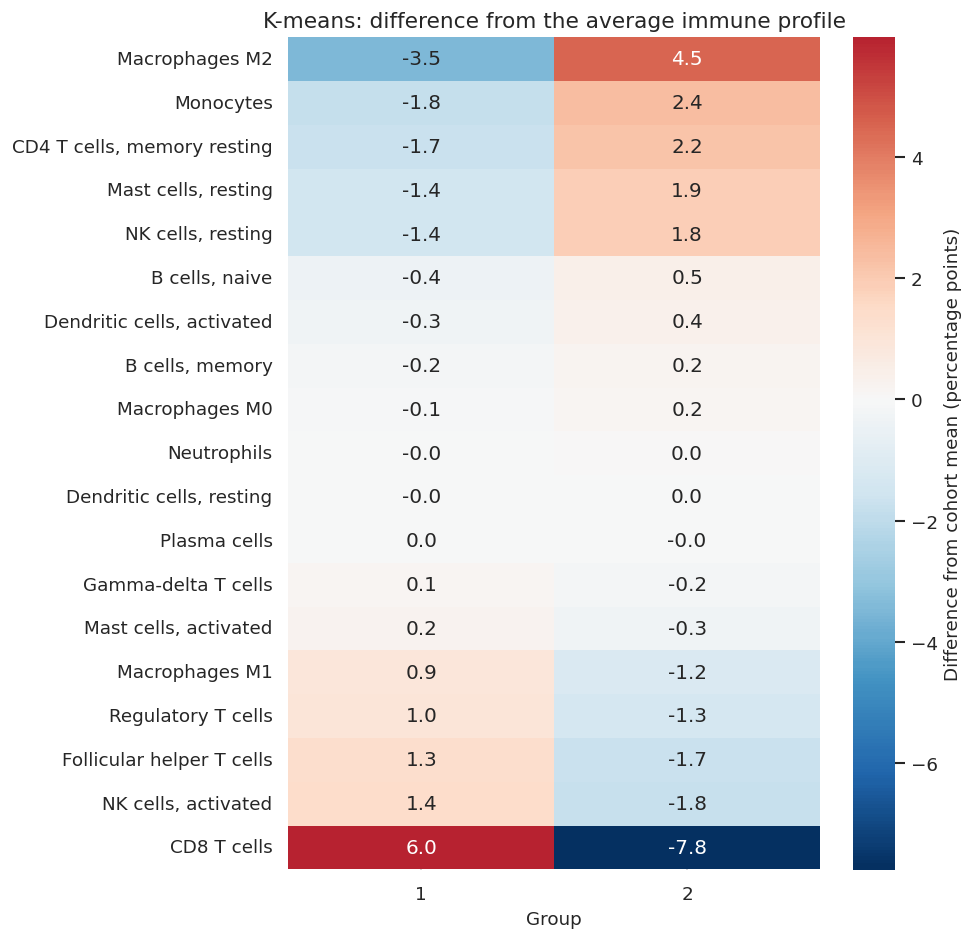

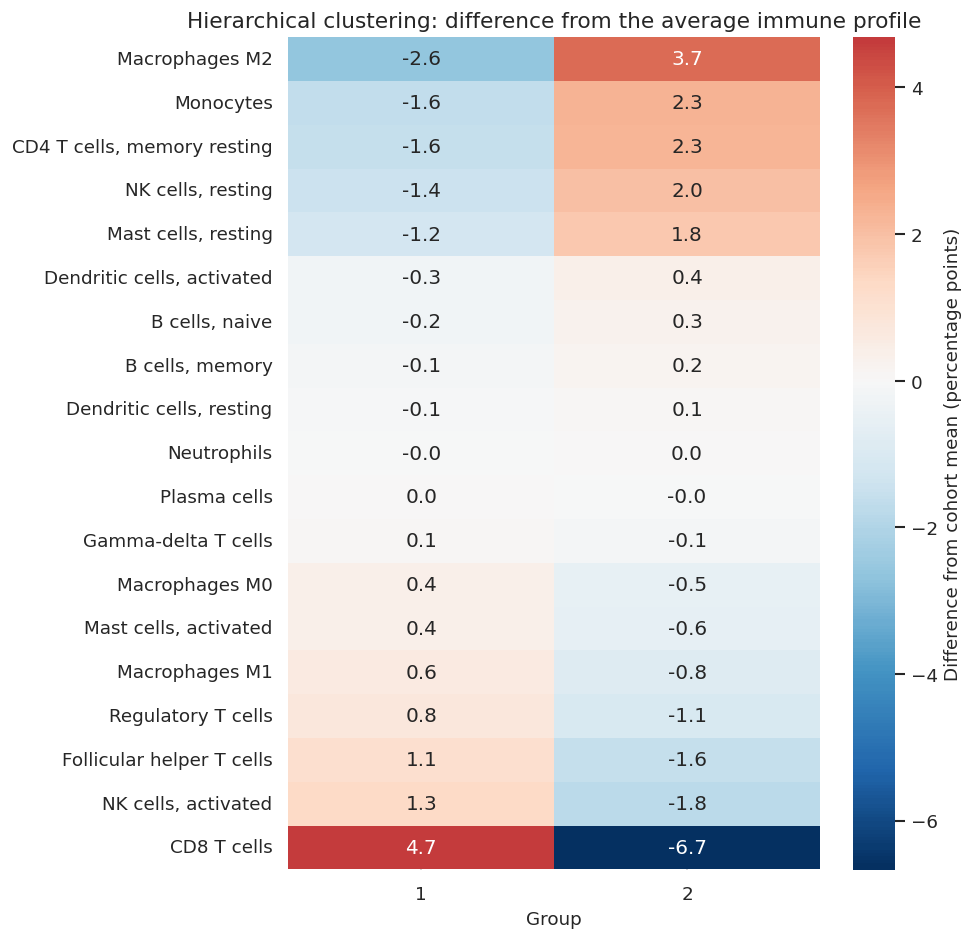

K-means stage counts


ajcc_pathologic_tumor_stage,Stage I,Stage II,Stage III,Stage IV,Unknown
cluster,,,,,
1,129,31,78,60,3
2,138,26,45,23,0


K-means grade counts


histological_grade,G1,G2,G3,G4,Unknown
cluster,,,,,
1,4,108,131,57,1
2,10,121,75,19,7


Hierarchical stage counts


ajcc_pathologic_tumor_stage,Stage I,Stage II,Stage III,Stage IV,Unknown
cluster,,,,,
1,139,35,78,58,3
2,128,22,45,25,0


Hierarchical grade counts


histological_grade,G1,G2,G3,G4,Unknown
cluster,,,,,
1,5,112,141,53,2
2,9,117,65,23,6


In [11]:
def immune_difference_table(labels):
    rows = []
    overall = proportions.mean()
    for cluster in sorted(np.unique(labels)):
        in_group = labels == cluster
        means = proportions.loc[in_group].mean()
        difference = (means - overall) * 100
        for feature in proportions.columns:
            rows.append(
                {
                    "cluster": int(cluster),
                    "feature": feature,
                    "display_name": display_name(feature),
                    "mean_percent": 100 * means[feature],
                    "difference_percentage_points": difference[feature],
                }
            )
    return pd.DataFrame(rows)


def plot_immune_heatmap(immune, title, filename):
    heat = immune.pivot(index="display_name", columns="cluster", values="difference_percentage_points")
    # put the cell type with the biggest average gap at the top
    order = heat.mean(axis=1).sort_values(ascending=False).index
    heat = heat.loc[order]
    fig, ax = plt.subplots(figsize=(1.6 * heat.shape[1] + 5, 8))
    sns.heatmap(
        heat,
        cmap="RdBu_r",
        center=0,
        annot=True,
        fmt=".1f",
        ax=ax,
        cbar_kws={"label": "Difference from cohort mean (percentage points)"},
    )
    ax.set_xlabel("Group")
    ax.set_ylabel("")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    plt.show()


def clinical_tables(labels):
    described = cohort.copy()
    described["cluster"] = labels
    stage = pd.crosstab(
        described["cluster"],
        described["ajcc_pathologic_tumor_stage"].fillna("Unknown"),
        dropna=False,
    )
    grade = pd.crosstab(
        described["cluster"],
        described["histological_grade"].fillna("Unknown"),
        dropna=False,
    )

    stage_cols = []
    for name in STAGE_ORDER:
        if name in stage.columns:
            stage_cols.append(name)
    grade_cols = []
    for name in GRADE_ORDER:
        if name in grade.columns:
            grade_cols.append(name)

    stage = stage.reindex(columns=stage_cols, fill_value=0)
    grade = grade.reindex(columns=grade_cols, fill_value=0)
    return stage, grade


kmeans_immune = immune_difference_table(kmeans_labels)
hierarchical_immune = immune_difference_table(hierarchical_labels)
plot_immune_heatmap(
    kmeans_immune,
    "K-means: difference from the average immune profile",
    "kmeans_immune_heatmap.png",
)
plot_immune_heatmap(
    hierarchical_immune,
    "Hierarchical clustering: difference from the average immune profile",
    "hierarchical_immune_heatmap.png",
)

print("K-means stage counts")
kmeans_stage, kmeans_grade = clinical_tables(kmeans_labels)
display(kmeans_stage)
print("K-means grade counts")
display(kmeans_grade)
print("Hierarchical stage counts")
hierarchical_stage, hierarchical_grade = clinical_tables(hierarchical_labels)
display(hierarchical_stage)
print("Hierarchical grade counts")
display(hierarchical_grade)


This step compares each group's immune cell mix, stage, and grade with the whole cohort. In both methods one group is higher in CD8 T cells and the other is higher in M2 macrophages. The CD8 group has more stage IV tumors ( about 19% to 20% ) and the macrophage group has more stage I tumors ( about 58% to 60% ). Where a patient sits on this immune split lines up with how advanced the tumor is.



## 8. Survival after the groups are fixed

Kaplan Meier curves use follow up time and count patients who are still alive as censored. The log rank p value compares the curves. It is not used to choose the groups.



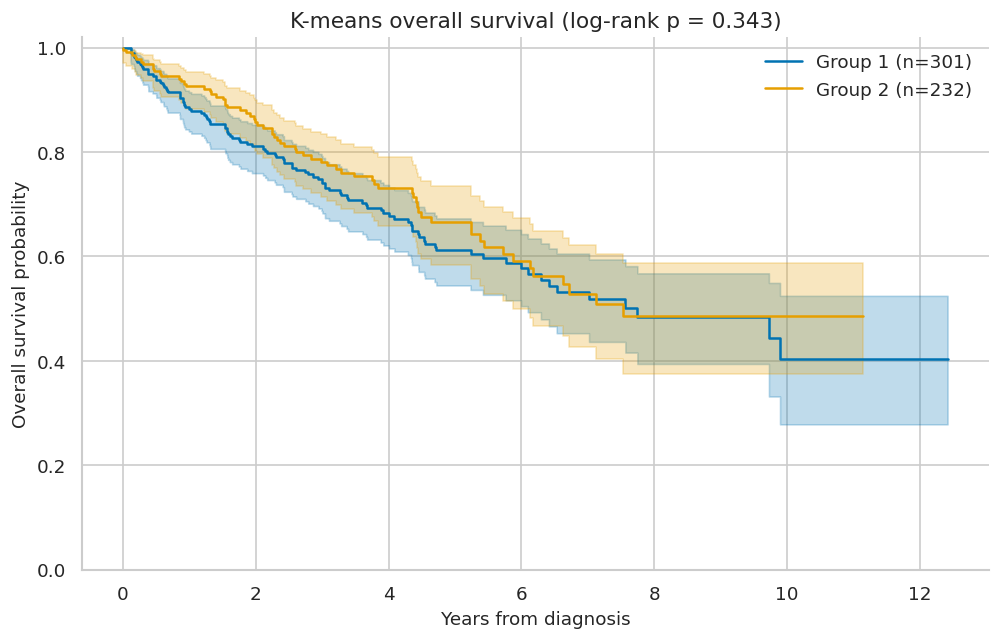

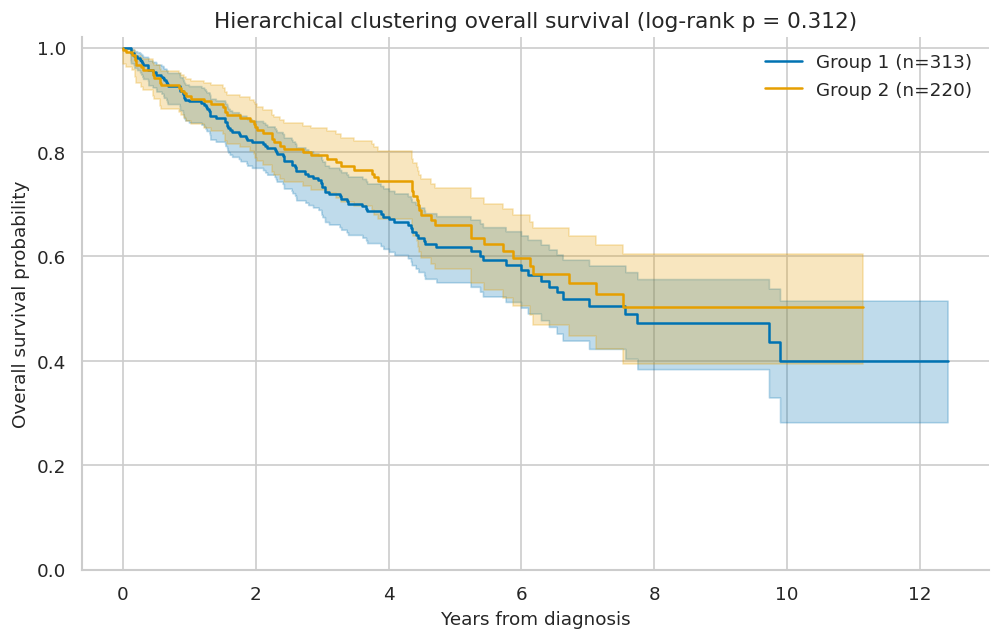

,cluster,n,n_deaths,median_survival_years,survival_at_3_years
0,1,301,107,7.748,0.744
1,2,232,68,7.535,0.781


,test,statistic,p_value,n
0,K-means overall survival,0.8999,0.3428,533


,cluster,n,n_deaths,median_survival_years,survival_at_3_years
0,1,313,110,7.567,0.737
1,2,220,65,NaN,0.794


,test,statistic,p_value,n
0,Hierarchical clustering overall survival,1.0202,0.3125,533


In [12]:
def survival_for(labels, title, filename):
    # survival was not used to make the groups. This only describes them.
    described = cohort.dropna(subset=["OS", "OS.time"]).copy()
    described["cluster"] = labels[described.index]
    described["years"] = described["OS.time"] / YEAR_DAYS

    result = multivariate_logrank_test(
        described["years"],
        described["cluster"].astype(str),
        described["OS"].astype(int),
    )

    rows = []
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    clusters = sorted(described["cluster"].unique())
    for cluster in clusters:
        group = described[described["cluster"] == cluster]
        km = KaplanMeierFitter()
        km.fit(group["years"], group["OS"].astype(int), label="Group " + str(cluster) + " (n=" + str(len(group)) + ")")
        km.plot_survival_function(ax=ax, ci_show=True, color=CLUSTER_COLORS[int(cluster) - 1])
        median_years = km.median_survival_time_
        if np.isfinite(median_years):
            median_to_save = median_years
        else:
            median_to_save = np.nan
        rows.append(
            {
                "cluster": int(cluster),
                "n": len(group),
                "n_deaths": int(group["OS"].sum()),
                "median_survival_years": median_to_save,
                "survival_at_3_years": float(km.predict(3)),
            }
        )

    ax.set_xlabel("Years from diagnosis")
    ax.set_ylabel("Overall survival probability")
    ax.set_ylim(0, 1.02)
    ax.set_title(title + " (log-rank p = " + format(result.p_value, ".3f") + ")")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    plt.show()

    summary = pd.DataFrame(rows)
    test = pd.DataFrame(
        [{"test": title, "statistic": result.test_statistic, "p_value": result.p_value, "n": len(described)}]
    )
    return summary, test


kmeans_survival, kmeans_logrank = survival_for(
    kmeans_labels,
    "K-means overall survival",
    "kmeans_km_survival.png",
)
hierarchical_survival, hierarchical_logrank = survival_for(
    hierarchical_labels,
    "Hierarchical clustering overall survival",
    "hierarchical_km_survival.png",
)
display(kmeans_survival.round(3))
display(kmeans_logrank.round(4))
display(hierarchical_survival.round(3))
display(hierarchical_logrank.round(4))


This step draws Kaplan Meier survival curves for each grouping and runs a log rank test. Survival was not used to make the groups. K means has a p value of 0.34 with median survival of 7.8 and 7.5 years. hierarchical clustering has a p value of 0.31. Neither grouping separates patients who live longer from patients who live shorter.



## 9. Save the tables

Patient-level group labels are written to `SIADS_696_outputs/processed`. Summary tables are written to `SIADS_696_outputs/tables`.



In [13]:
patient_results = cohort.copy()
patient_results["kmeans_cluster"] = kmeans_labels
patient_results["hierarchical_cluster"] = hierarchical_labels

# write the tables to Google Drive
kmeans_table.to_csv(TABLE_DIR / "kmeans_selection.csv", index=False)
hierarchical_table.to_csv(TABLE_DIR / "hierarchical_selection.csv", index=False)
comparison.to_csv(TABLE_DIR / "method_comparison.csv", index=False)
kmeans_immune.to_csv(TABLE_DIR / "kmeans_immune_means.csv", index=False)
hierarchical_immune.to_csv(TABLE_DIR / "hierarchical_immune_means.csv", index=False)
kmeans_stage.to_csv(TABLE_DIR / "kmeans_stage_counts.csv")
hierarchical_stage.to_csv(TABLE_DIR / "hierarchical_stage_counts.csv")
kmeans_grade.to_csv(TABLE_DIR / "kmeans_grade_counts.csv")
hierarchical_grade.to_csv(TABLE_DIR / "hierarchical_grade_counts.csv")
kmeans_survival.to_csv(TABLE_DIR / "kmeans_survival.csv", index=False)
hierarchical_survival.to_csv(TABLE_DIR / "hierarchical_survival.csv", index=False)
kmeans_logrank.to_csv(TABLE_DIR / "kmeans_logrank.csv", index=False)
hierarchical_logrank.to_csv(TABLE_DIR / "hierarchical_logrank.csv", index=False)
delta_table.to_csv(TABLE_DIR / "zero_replacement_values.csv", index=False)
patient_results.to_csv(PROCESSED_DIR / "kirc_unsupervised_patient_results.csv", index=False)

print("Saved patient results and summary tables.")
display(patient_results[["patient_id", "kmeans_cluster", "hierarchical_cluster"]].head())


Saved patient results and summary tables.


,patient_id,kmeans_cluster,hierarchical_cluster
0,TCGA-3Z-A93Z,2,2
1,TCGA-6D-AA2E,1,1
2,TCGA-A3-3306,1,1
3,TCGA-A3-3307,1,1
4,TCGA-A3-3308,2,2


## 10. Check: clustering after PCA

This check compresses the same 19 standardized features with PCA and keeps the smallest number of components that explain at least 80% of the variance. It then repeats k-means and hierarchical clustering with the same rules. It does not replace the groups above.

In [14]:
from sklearn.decomposition import PCA

# compress the same 19 features
pca = PCA(svd_solver="full", random_state=RANDOM_STATE)
pca_scores_all = pca.fit_transform(scaled)
variance = pca.explained_variance_ratio_
cumulative = np.cumsum(variance)

# keep the smallest number of components that explain at least 80%
n_components = int(np.searchsorted(cumulative, VARIANCE_TARGET) + 1)
if n_components > len(variance):
    n_components = len(variance)

pca_scores = pca_scores_all[:, :n_components].copy()
loadings = pca.components_[:n_components].copy()

# flip a component when its strongest weight is negative
for component in range(n_components):
    strongest = np.argmax(np.abs(loadings[component]))
    if loadings[component, strongest] < 0:
        loadings[component] = loadings[component] * -1
        pca_scores[:, component] = pca_scores[:, component] * -1

component_names = []
for i in range(1, n_components + 1):
    component_names.append("PC" + str(i))

pca_variance = pd.DataFrame(
    {
        "component": component_names,
        "explained_variance": variance[:n_components],
        "cumulative_variance": cumulative[:n_components],
    }
)

pca_kmeans_table, pca_kmeans_k, pca_kmeans_labels = choose_k_means(pca_scores, min_size)

# cut the PCA tree the same way, from 2 through 8 groups
pca_link = linkage(pca_scores, method="ward", metric="euclidean")
pca_hierarchical_rows = []
pca_hierarchical_fits = {}
for k in K_RANGE:
    raw_labels = fcluster(pca_link, t=k, criterion="maxclust")
    labels = relabel_by_size(raw_labels)
    sizes = np.bincount(labels)[1:]
    pca_hierarchical_rows.append(
        {
            "k": k,
            "silhouette": silhouette_score(pca_scores, labels),
            "min_cluster_size": int(sizes.min()),
            "max_cluster_size": int(sizes.max()),
            "meets_size_rule": bool(sizes.min() >= min_size),
        }
    )
    pca_hierarchical_fits[k] = labels

pca_hierarchical_table = pd.DataFrame(pca_hierarchical_rows)
pca_hierarchical_eligible = pca_hierarchical_table[pca_hierarchical_table["meets_size_rule"] == True]
if len(pca_hierarchical_eligible) == 0:
    raise ValueError("No PCA hierarchical cut met the minimum group-size rule.")

best_row = pca_hierarchical_eligible["silhouette"].idxmax()
pca_hierarchical_k = int(pca_hierarchical_eligible.loc[best_row, "k"])
pca_hierarchical_labels = pca_hierarchical_fits[pca_hierarchical_k]

kmeans_switched = int(np.sum(kmeans_labels != pca_kmeans_labels))
hierarchical_switched = int(np.sum(hierarchical_labels != pca_hierarchical_labels))
pca_agreement = pd.DataFrame(
    [
        {
            "comparison": "K-means, 19 features vs PCA scores",
            "groups_on_features": kmeans_k,
            "groups_on_pca": pca_kmeans_k,
            "adjusted_rand": adjusted_rand_score(kmeans_labels, pca_kmeans_labels),
            "patients_switched": kmeans_switched,
        },
        {
            "comparison": "Hierarchical, 19 features vs PCA scores",
            "groups_on_features": hierarchical_k,
            "groups_on_pca": pca_hierarchical_k,
            "adjusted_rand": adjusted_rand_score(hierarchical_labels, pca_hierarchical_labels),
            "patients_switched": hierarchical_switched,
        },
    ]
)

print("PCA components kept:", n_components)
print("Variance kept:", round(100 * cumulative[n_components - 1], 1), "%")
print("K-means on PCA scores:", pca_kmeans_k)
display(pca_kmeans_table.round(3))
print("Hierarchical clustering on PCA scores:", pca_hierarchical_k)
display(pca_hierarchical_table.round(3))
display(pca_agreement.round(3))
print("K-means, features vs PCA")
display(pd.crosstab(
    pd.Series(kmeans_labels, name="19 features"),
    pd.Series(pca_kmeans_labels, name="PCA scores"),
))
print("Hierarchical, features vs PCA")
display(pd.crosstab(
    pd.Series(hierarchical_labels, name="19 features"),
    pd.Series(pca_hierarchical_labels, name="PCA scores"),
))

pca_variance.to_csv(TABLE_DIR / "pca_variance.csv", index=False)
pca_kmeans_table.to_csv(TABLE_DIR / "pca_kmeans_selection.csv", index=False)
pca_hierarchical_table.to_csv(TABLE_DIR / "pca_hierarchical_selection.csv", index=False)
pca_agreement.to_csv(TABLE_DIR / "pca_agreement.csv", index=False)


PCA components kept: 10
Variance kept: 80.4 %
K-means on PCA scores: 2


,k,silhouette,calinski_harabasz,davies_bouldin,min_cluster_size,max_cluster_size,meets_size_rule
0,2,0.151,96.899,2.252,235,298,True
1,3,0.135,80.063,2.171,131,210,True
2,4,0.126,70.003,2.030,86,177,True
3,5,0.124,63.737,2.042,48,151,True
4,6,0.116,59.637,1.975,51,133,True
5,7,0.124,56.078,1.916,17,143,False
6,8,0.114,53.386,1.863,17,99,False


Hierarchical clustering on PCA scores: 2


,k,silhouette,min_cluster_size,max_cluster_size,meets_size_rule
0,2,0.135,228,305,True
1,3,0.126,92,228,True
2,4,0.114,63,228,True
3,5,0.107,60,168,True
4,6,0.114,15,168,False
5,7,0.073,15,168,False
6,8,0.081,15,139,False


,comparison,groups_on_features,groups_on_pca,adjusted_rand,patients_switched
0,"K-means, 19 features vs PCA scores",2,2,0.963,5
1,"Hierarchical, 19 features vs PCA scores",2,2,0.709,42


K-means, features vs PCA


PCA scores,1,2
19 features,,
1,297,4
2,1,231


Hierarchical, features vs PCA


PCA scores,1,2
19 features,,
1,288,25
2,17,203


This step compresses the 19 features into 10 PCA scores that keep 80.4% of the variance then repeats both clustering methods. K means again chooses 2 groups  with 298 and 235 patients and a silhouette score of 0.15. Only 5 patients switch groups and the Adjusted Rand Index is 0.96. Hierarchical clustering also chooses 2 groups with 305 and 228 patients and a silhouette score of 0.14. About 42 patients switch groups and the Adjusted Rand Index is 0.71. Compressing the features does not create a different grouping. K means is almost unchanged and hierarchical clustering still finds the same two group split.

The 533 patients do not form two tight immune groups. K-means and hierarchical clustering both settle on 2 groups but the silhouette scores are weak ( 0.13 and 0.11 ) so the patients overlap. The two methods mostly agree. One group is higher in CD8 T cells and has more stage IV tumors ( about 19% to 20% ). The other group is higher in M2 macrophages and has more stage I tumors ( about 58% to 60% ). Where a patient sits on this split lines up with how advanced the tumor is. It does not separate patients who live longer from patients who live shorter. The log rank p-values are 0.34 for k means and 0.31 for hierarchical clustering. Repeating the clustering after PCA gives the same pattern.

That is a group pattern. Plenty of stage I patients sit on the CD8 end and some stage IV patients sit on the macrophage end. The immune mix also does not separate patients who live longer from patients who live shorter. So the spectrum describes the immune profile and tracks stage in the cohort.